In [8]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

HERE = Path("/Users/temp/Documents/GitHub/Negotiating-Space/Behavioral_Vision_Pipeline")
config = yaml.safe_load(open(HERE / "Data_Config" / "paths.yaml"))
frames_dir = Path(config["data_dir"]) / config["camera_dir"]
images = sorted(frames_dir.glob("*.png"))
print(len(images))

401


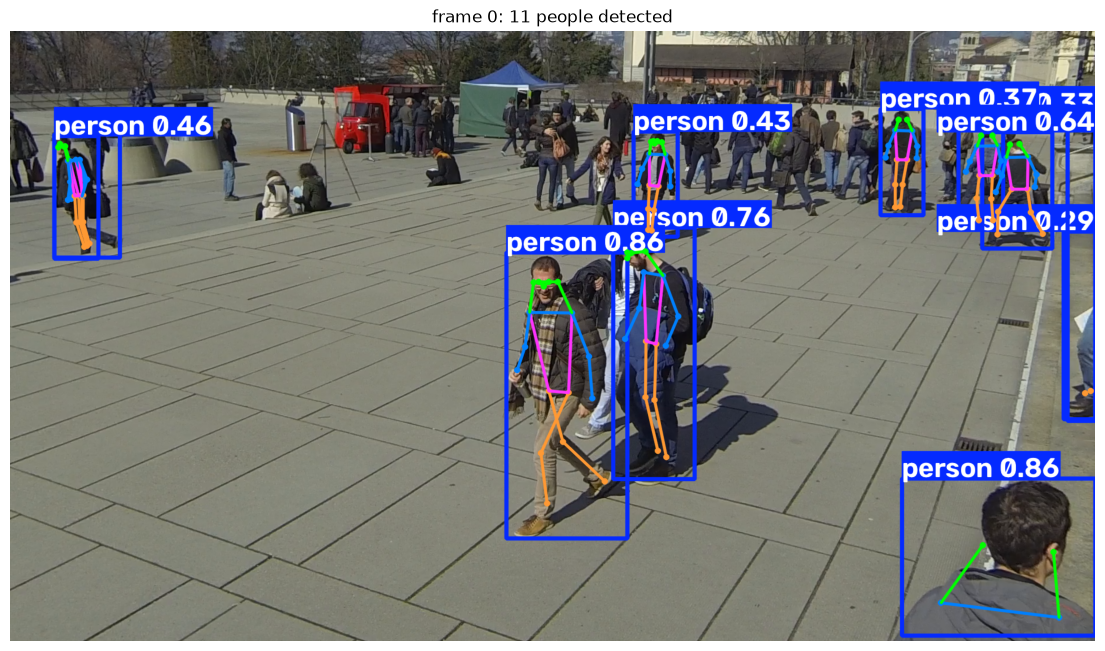

In [9]:
model = YOLO("yolov8n-pose.pt")


def show(i, model=model):
    r = model(str(images[i]), verbose=False)[0]
    plt.figure(figsize=(14, 8))
    plt.imshow(r.plot()[:, :, ::-1])  # plot() returns BGR; flip to RGB
    plt.title(f"frame {i}: {len(r.boxes)} people detected")
    plt.axis("off")
    plt.show()


show(0)

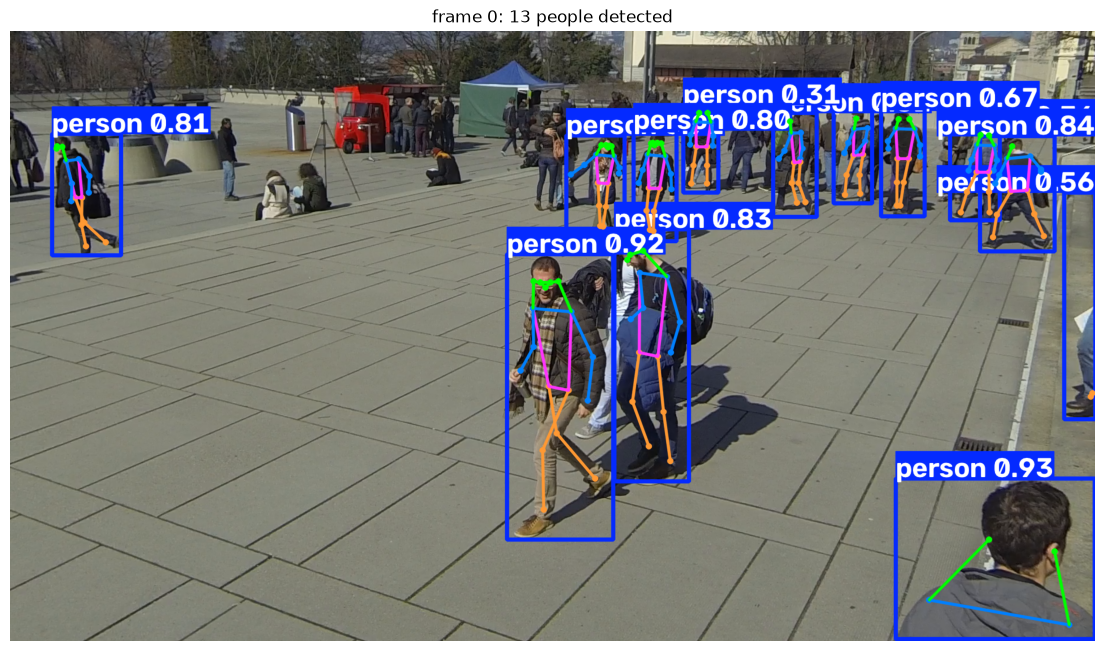

In [10]:
show(0, YOLO("yolov8m-pose.pt"))

In [11]:
df = pd.read_csv(HERE / config["output_dir"] / "tracks_C1.csv")
df.groupby("frame").size().describe()  # people per frame: mean, min, max

count    356.000000
mean       6.053371
std        2.508569
min        1.000000
25%        4.000000
50%        7.000000
75%        8.000000
max       11.000000
dtype: float64

In [12]:
def count(i, model_name, imgsz=640, conf=0.25):
    r = YOLO(model_name)(str(images[i]), imgsz=imgsz, conf=conf, verbose=False)[0]
    return len(r.boxes)


for model_name in ["yolov8n-pose.pt", "yolov8m-pose.pt"]:
    for imgsz in [640, 1280, 1920]:
        print(model_name, imgsz, count(0, model_name, imgsz, conf=0.15))

yolov8n-pose.pt 640 12
yolov8n-pose.pt 1280 32
yolov8n-pose.pt 1920 36
yolov8m-pose.pt 640 15
yolov8m-pose.pt 1280 24
yolov8m-pose.pt 1920 29


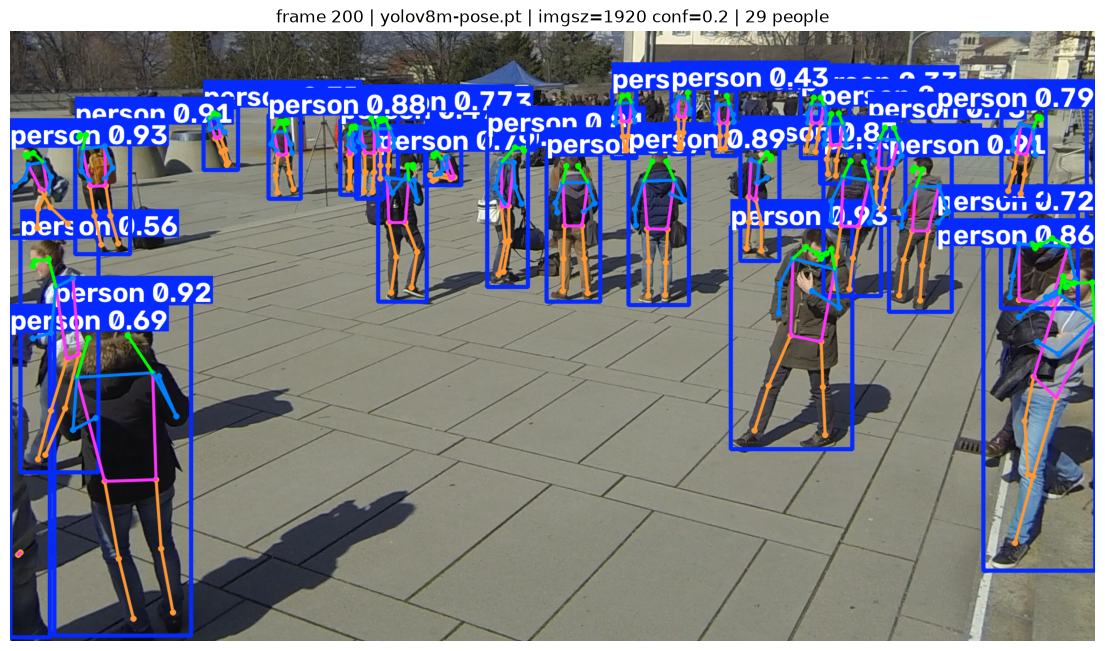

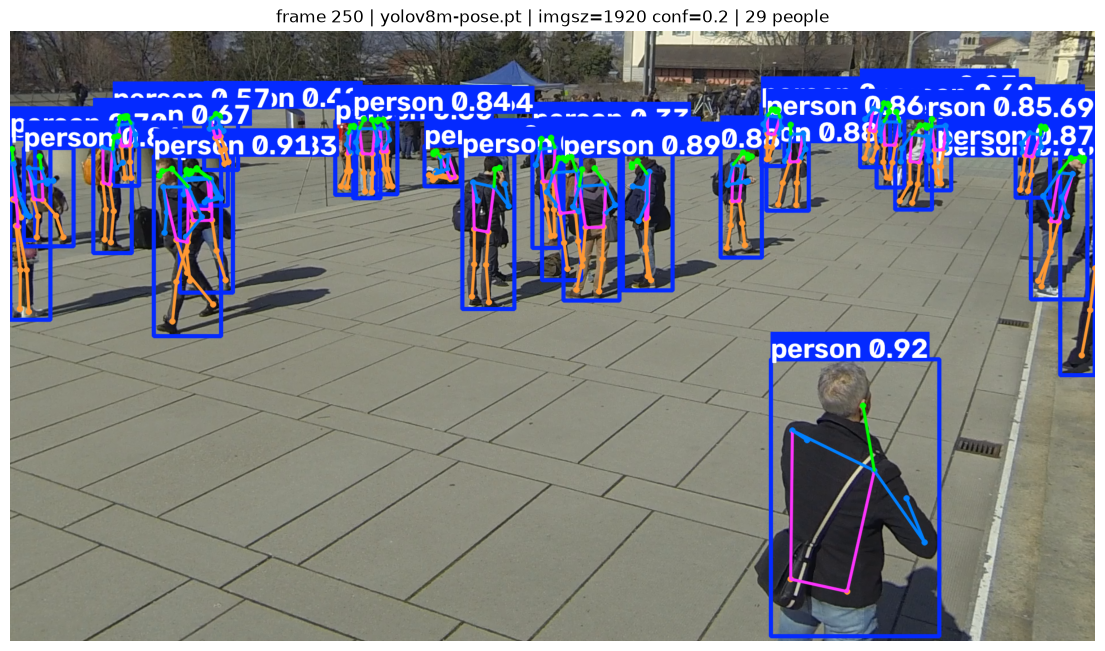

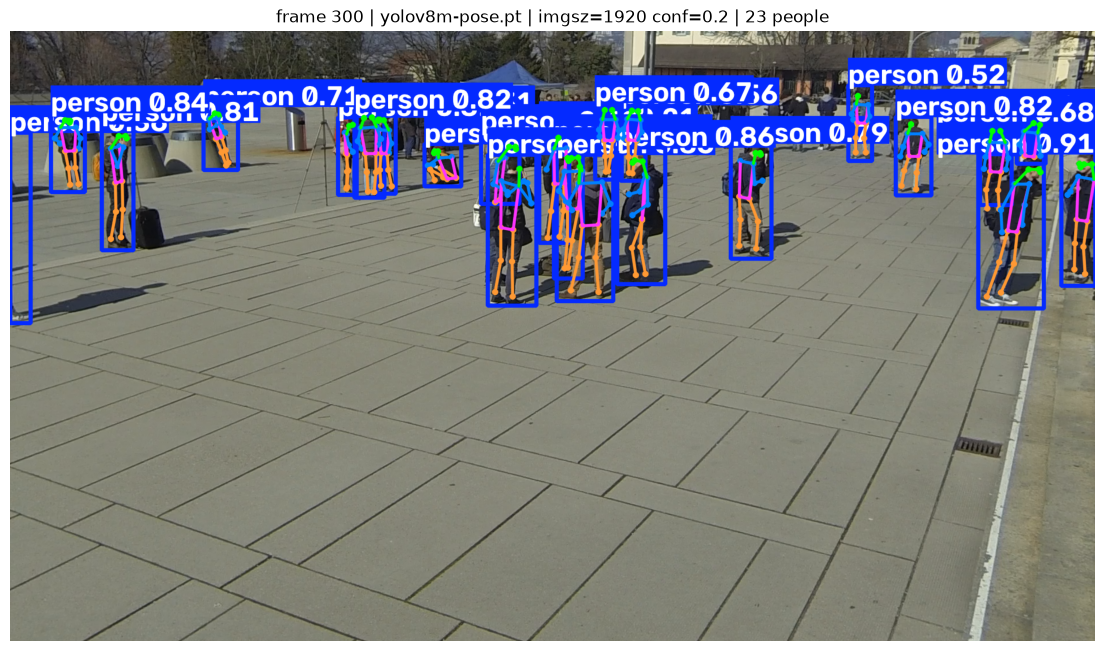

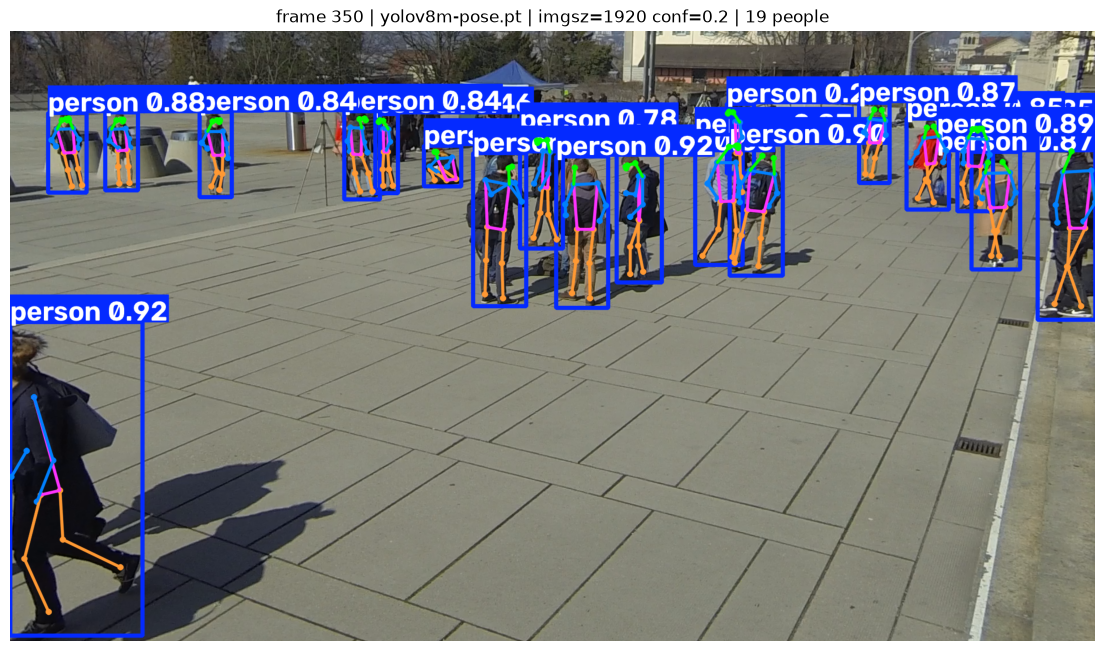

In [31]:
def show(i, model_name="yolov8m-pose.pt", imgsz=1920, conf=0.20):
    r = YOLO(model_name)(str(images[i]), imgsz=imgsz, conf=conf, verbose=False)[0]
    plt.figure(figsize=(14, 8))
    plt.imshow(r.plot()[:, :, ::-1])
    plt.title(
        f"frame {i} | {model_name} | imgsz={imgsz} conf={conf} | {len(r.boxes)} people"
    )
    plt.axis("off")
    plt.show()


show(200)
show(250)
show(300)
show(350)